# TMR: Text-to-Motion Retrieval — Merged Best Version

**Architecture**: Combines the proven BiGRU backbone (NOTEBOOK_FINAL, val=0.86) with the two-person interaction modeling from newass2, plus multi-positive loss and hard negative mining.

- **Text Encoder**: `all-mpnet-base-v2` + mean pooling + projection MLP (last 2 layers fine-tuned)
- **Motion Encoder**: **Gated Person Fusion** → BiGRU → Attention Pooling → Projection MLP
- **Loss**: Multi-positive InfoNCE + **progressive hard negative mining** + label smoothing

**Key improvements over NOTEBOOK_FINAL (0.86)**:
- **Gated Person Fusion** (from newass2): learns per-frame weighting between person 1 & 2 instead of blind concatenation — critical for asymmetric interactions (one leads, one follows)
- **embed_dim** 256 → 384: richer shared embedding space (matches motion input dimension)
- **Multi-positive InfoNCE**: same motion ID in batch → treated as mutual positives (correct with multi-text pairs)
- **Progressive hard negative mining**: ramps over 40 epochs, focuses on hardest in-batch negatives
- **Multi-text pairs**: all 3 texts/motion = 16 251 pairs vs 5 417 (3× supervision)
- **Speed jitter** (0.85–1.15×): temporal scale invariance
- **Top-3 checkpoint saving**: never lose a good intermediate model
- **Person-swap TTA** at inference: proven +2% on val

**Augmentations intentionally excluded**:
- ~~Mirror/flip~~: texts contain directional words ("to the left", "right hand") → mirrored motion + original text = false pair

In [26]:
import os
import glob
import math
import random
import csv
import copy
import numpy as np
import pandas as pd
from tqdm import tqdm
from os.path import join as pjoin

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sentence_transformers import SentenceTransformer

# ======================== AUTO-DETECT ENVIRONMENT ========================
def _detect_paths():
    if os.path.exists('/kaggle/input'):
        return dict(
            data_root = '/kaggle/input/tmr-text-motion-retrieval/data/data',
            test_dir  = '/kaggle/input/tmr-text-motion-retrieval/data/data/test',
            val_dir   = '/kaggle/working/val_generated',
        )
    if os.path.exists('/teamspace/studios/this_studio'):
        return dict(
            data_root = '/teamspace/studios/this_studio',
            test_dir  = '/teamspace/studios/this_studio/test',
            val_dir   = '/teamspace/studios/this_studio/val_generated',
        )
    # Local Windows / WSL
    base = r'C:\Users\bahma\PycharmProjects\Text-to-Motion'
    return dict(
        data_root = os.path.join(base, 'data'),
        test_dir  = os.path.join(base, 'data', 'test'),
        val_dir   = os.path.join(base, 'val_generated'),
    )

_paths = _detect_paths()

# ======================== CONFIGURATION ========================
class Config:
    data_root = _paths['data_root']
    test_dir  = _paths['test_dir']
    val_dir   = _paths['val_dir']

    # ----- Motion geometry -----
    motion_dim = 384
    person_dim = 192            # dims per person (motion_dim // 2)

    # ----- Motion encoder (BiGRU + Gated Person Fusion) -----
    gru_hidden = 256
    gru_layers = 2
    dropout    = 0.1
    embed_dim  = 384            # 256→384: richer space, matches motion_dim

    # ----- Text encoder (partially fine-tuned all-mpnet-base-v2) -----
    text_model_name      = 'sentence-transformers/all-mpnet-base-v2'
    text_emb_dim         = 768
    text_unfreeze_layers = 2    # last 2 transformer layers unfrozen
    text_encoder_lr      = 1e-5 # 50× lower than main LR

    # ----- Training -----
    batch_size        = 64
    grad_accum_steps  = 4       # effective batch = 256
    epochs            = 60
    lr                = 5e-4
    weight_decay      = 1e-3
    warmup_steps      = 300
    grad_clip         = 1.0
    label_smoothing   = 0.08

    # ----- Hard negative mining -----
    hn_beta_max    = 0.4
    hn_ramp_epochs = 40

    # ----- EMA -----
    ema_decay = 0.999

    # ----- Validation -----
    val_split       = 0.1
    val_batch_size  = 32
    val_num_batches = 18
    val_every       = 5

    # ----- Augmentation -----
    person_swap_prob   = 0.5
    gaussian_noise_std = 0.005
    temporal_crop_prob = 0.5
    temporal_crop_min  = 0.5
    speed_jitter_prob  = 0.3
    speed_jitter_range = (0.85, 1.15)
    max_motion_length  = 300

    # ----- Checkpoints -----
    save_top_k = 3

    # ----- Misc -----
    seed        = 42
    device      = 'cuda' if torch.cuda.is_available() else 'cpu'
    num_workers = 2
    use_amp     = True

cfg = Config()

random.seed(cfg.seed)
np.random.seed(cfg.seed)
torch.manual_seed(cfg.seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(cfg.seed)

print(f"Device    : {cfg.device}")
print(f"PyTorch   : {torch.__version__}")
print(f"data_root : {cfg.data_root}")
print(f"val_dir   : {cfg.val_dir}")
print(f"embed_dim : {cfg.embed_dim} | gru_hidden: {cfg.gru_hidden} | "
      f"label_smoothing: {cfg.label_smoothing} | hn_beta_max: {cfg.hn_beta_max}")

Device    : cuda
PyTorch   : 2.8.0+cu126
data_root : /kaggle/input/tmr-text-motion-retrieval/data/data
val_dir   : /kaggle/working/val_generated
embed_dim : 384 | gru_hidden: 256 | label_smoothing: 0.08 | hn_beta_max: 0.4


## 1. Evaluation & Validation Utilities

In [27]:
# ======================== EVALUATION ========================

def eval_recall(gt_df, pred_df, verbose=False):
    """Compute weighted Recall@K score (official metric)."""
    ks = list(range(1, 11))
    rank_cols = list(pred_df.columns)
    gt = gt_df["candidate"].values
    preds = pred_df[rank_cols].values
    assert len(gt) == len(preds), "size mismatch"

    recalls = {k: 0 for k in ks}
    n = len(gt)
    for i in range(n):
        for k in ks:
            if gt[i] in preds[i, :k]:
                recalls[k] += 1
    for k in ks:
        recalls[k] /= n

    weights = {k: 1.0 / k for k in ks}
    weight_sum = sum(weights.values())
    final_score = sum(weights[k] * recalls[k] for k in ks) / weight_sum

    if verbose:
        for k, val in recalls.items():
            print(f'  Recall@{k} = {val:.3f}')
    return final_score


# ======================== VALIDATION BATCH GENERATION ========================

def generate_val_batches(data_root, save_dir, batch_size, num_batches, val_ids):
    """Generate validation batches from held-out validation IDs (no data leakage)."""
    os.makedirs(save_dir, exist_ok=True)

    # Cap num_batches so we don't exceed available val samples
    max_batches = len(val_ids) // batch_size
    if num_batches > max_batches:
        print(f"  Capping val batches: {num_batches} -> {max_batches} "
              f"({len(val_ids)} val IDs / {batch_size} per batch)")
        num_batches = max_batches

    random_fnames = random.sample(val_ids, k=batch_size * num_batches)
    random_batches = np.array(random_fnames).reshape(num_batches, batch_size)

    gt = [['query_id', 'candidate']]
    for file_idx, batch in enumerate(random_batches, start=1):
        os.makedirs(pjoin(save_dir, str(file_idx)), exist_ok=True)

        rdm_idx = random.randint(0, len(batch) - 1)
        random_text_fname = batch[rdm_idx]

        with open(os.path.join(data_root, 'texts', random_text_fname + '.txt')) as fd:
            file_texts = fd.read().strip().split('\n')
            random_text = random.choice(file_texts)

        with open(os.path.join(save_dir, str(file_idx), 'text.txt'), 'w') as fw:
            fw.write(random_text)

        for motion_idx, fname in enumerate(batch, start=1):
            if fname == random_text_fname:
                gt.append([file_idx, motion_idx])
            motion = np.load(os.path.join(data_root, 'motions', fname + '.npy'))

            np.save(pjoin(save_dir, str(file_idx), f'motion_{motion_idx}.npy'), motion)

    with open(os.path.join(save_dir, 'gt.csv'), 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerows(gt)

    print(f'Validation batches saved at {save_dir}')

## 2. Dataset & DataLoader

In [28]:
# ======================== DATA LOADING ========================

def load_train_data(data_root, val_split=0.1, seed=42):
    """Load motion IDs and texts with deterministic train/val split."""
    with open(os.path.join(data_root, 'train.txt')) as f:
        all_ids = f.read().strip().split('\n')
    
    texts_dict = {}
    for mid in all_ids:
        with open(os.path.join(data_root, 'texts', f'{mid}.txt')) as f:
            texts = [t.strip() for t in f.read().strip().split('\n') if t.strip()]
            texts_dict[mid] = texts
    
    rng = random.Random(seed)
    shuffled = all_ids[:]
    rng.shuffle(shuffled)
    n_val = int(len(shuffled) * val_split)
    val_ids = shuffled[:n_val]
    train_ids = shuffled[n_val:]
    
    print(f"Total: {len(all_ids)} | Train: {len(train_ids)} | Val: {len(val_ids)}")
    print(f"Average texts per motion: {np.mean([len(v) for v in texts_dict.values()]):.1f}")
    return train_ids, val_ids, texts_dict


# ======================== AUGMENTATION HELPERS ========================

def speed_jitter(motion, factor_range=(0.85, 1.15)):
    """Temporally resample motion to simulate different movement speeds.
    
    Safe for contrastive learning: does not alter semantic content
    (no directional change, no person identity change).
    """
    T = motion.shape[0]
    factor = random.uniform(*factor_range)
    new_T = max(4, int(T * factor))
    x_old = np.linspace(0, 1, T)
    x_new = np.linspace(0, 1, new_T)
    return np.array(
        [np.interp(x_new, x_old, motion[:, d]) for d in range(motion.shape[1])]
    ).T.astype(np.float32)


# ======================== DATASET ========================

class MotionTextDataset(Dataset):
    def __init__(self, motion_ids, texts_dict, data_root, cfg, augment=True):
        self.texts_dict = texts_dict
        self.data_root = data_root
        self.max_length = cfg.max_motion_length
        self.augment = augment
        self.person_swap_prob = cfg.person_swap_prob
        self.noise_std = cfg.gaussian_noise_std
        self.crop_prob = cfg.temporal_crop_prob
        self.crop_min = cfg.temporal_crop_min
        self.speed_jitter_prob = cfg.speed_jitter_prob
        self.speed_jitter_range = cfg.speed_jitter_range
        
        print("Preloading motions into RAM...")
        self.motions = {}
        for mid in tqdm(motion_ids, desc='Loading'):
            self.motions[mid] = np.load(
                os.path.join(data_root, 'motions', f'{mid}.npy')
            ).astype(np.float32)
        print(f"Loaded {len(self.motions)} motions")
        
        # Normalization stats (computed from motions, not pairs)
        print("Computing normalization stats...")
        all_frames = np.concatenate(list(self.motions.values()), axis=0)
        self.motion_mean = all_frames.mean(axis=0).astype(np.float32)
        raw_std = all_frames.std(axis=0).astype(np.float32)
        self.motion_std = np.clip(raw_std, a_min=1e-2, a_max=None)
        n_clamped = int((raw_std < 1e-2).sum())
        del all_frames
        print(f"  Mean range: [{self.motion_mean.min():.3f}, {self.motion_mean.max():.3f}]")
        print(f"  Std range:  [{self.motion_std.min():.3f}, {self.motion_std.max():.3f}]")
        if n_clamped > 0:
            print(f"  WARNING: {n_clamped}/{len(raw_std)} features clamped (near-zero std)")
        
        # ── KEY CHANGE: one training pair per (motion, text) combination ──
        # With ~3 texts per motion this triples the number of training pairs
        # and ensures every text description is seen each epoch.
        self.pairs = [
            (mid, text)
            for mid in motion_ids
            for text in texts_dict[mid]
        ]
        print(f"Training pairs: {len(self.pairs)} "
              f"({len(motion_ids)} motions × "
              f"{len(self.pairs)/len(motion_ids):.1f} texts/motion avg)")
    
    def __len__(self):
        return len(self.pairs)
    
    def __getitem__(self, idx):
        mid, text = self.pairs[idx]
        motion = self.motions[mid].copy()
        
        if self.augment:
            # 1. Temporal crop
            if random.random() < self.crop_prob and motion.shape[0] > 10:
                crop_ratio = random.uniform(self.crop_min, 1.0)
                crop_len = max(10, int(motion.shape[0] * crop_ratio))
                start = random.randint(0, motion.shape[0] - crop_len)
                motion = motion[start:start + crop_len]
            
            # 2. Speed jitter (temporal scale invariance)
            if random.random() < self.speed_jitter_prob and motion.shape[0] > 4:
                motion = speed_jitter(motion, self.speed_jitter_range)
            
            # 3. Person swap
            if random.random() < self.person_swap_prob:
                motion = np.concatenate([motion[:, 192:], motion[:, :192]], axis=1)
            
            # 4. Gaussian noise
            if self.noise_std > 0:
                noise = np.random.randn(*motion.shape).astype(np.float32) * self.noise_std
                motion = motion + noise
        
        if motion.shape[0] > self.max_length:
            motion = motion[:self.max_length]
        
        return {
            'motion': torch.from_numpy(motion),
            'text': text,
            'motion_id': mid
        }


def collate_fn(batch):
    motions = [b['motion'] for b in batch]
    texts = [b['text'] for b in batch]
    motion_ids = [b['motion_id'] for b in batch]
    
    max_len = max(m.shape[0] for m in motions)
    B = len(motions)
    D = motions[0].shape[1]
    padded = torch.zeros(B, max_len, D)
    masks = torch.zeros(B, max_len, dtype=torch.bool)
    lengths = torch.zeros(B, dtype=torch.long)
    
    for i, m in enumerate(motions):
        T = m.shape[0]
        padded[i, :T] = m
        masks[i, :T] = True
        lengths[i] = T

    return {
        'motions': padded,
        'masks': masks,
        'lengths': lengths,
        'texts': texts,
        'motion_ids': motion_ids
    }

## 3. Model Architecture

- **GatedPersonFusion**: splits 384-dim input into two 192-dim person streams, learns per-frame gate weights — better than blind linear projection for asymmetric 2-person interactions
- **MotionEncoder**: GatedPersonFusion → LayerNorm → GELU → BiGRU (2 layers, bidir) → AttentionPooling → Projection MLP
- **TextEncoder**: Frozen `all-mpnet-base-v2` (last 2 layers fine-tuned) → mean pooling → Projection MLP
- **TMRModel**: Multi-positive InfoNCE with hard negative mining and learnable temperature

In [29]:
# ======================== MODEL ========================

class AttentionPooling(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(input_dim, input_dim),
            nn.Tanh(),
            nn.Linear(input_dim, 1)
        )

    def forward(self, x, mask):
        attn_weights = self.attention(x).squeeze(-1)
        attn_weights = attn_weights.masked_fill(~mask, float('-inf'))
        attn_weights = F.softmax(attn_weights, dim=-1)
        return torch.bmm(attn_weights.unsqueeze(1), x).squeeze(1)


class GatedPersonFusion(nn.Module):
    """
    Learns per-frame, per-dimension weights between person 1 and person 2.

    Why this beats a simple Linear(384, hidden):
    - Interaction motions are often asymmetric: one person initiates (sword strike),
      the other reacts (parry). The gate learns WHICH person's signal matters per frame.
    - Each person gets its own projection (proj1, proj2), so representations stay
      disentangled before fusion, reducing cross-person feature leakage.

    Input : (B, T, person_dim * 2)   e.g. (B, T, 384)
    Output: (B, T, out_dim)          e.g. (B, T, 256)
    """
    def __init__(self, person_dim, out_dim):
        super().__init__()
        self.proj1 = nn.Linear(person_dim, out_dim)
        self.proj2 = nn.Linear(person_dim, out_dim)
        # Gate sees the full motion (both persons) to capture interaction context
        self.gate  = nn.Sequential(
            nn.Linear(person_dim * 2, out_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        half = x.shape[-1] // 2
        p1, p2 = x[:, :, :half], x[:, :, half:]
        g = self.gate(x)                            # (B, T, out_dim)
        return g * self.proj1(p1) + (1 - g) * self.proj2(p2)


class MotionEncoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.register_buffer('motion_mean', torch.zeros(cfg.motion_dim))
        self.register_buffer('motion_std',  torch.ones(cfg.motion_dim))

        # Gated fusion replaces the simple Linear(384, hidden) projection
        self.input_proj = nn.Sequential(
            GatedPersonFusion(cfg.person_dim, cfg.gru_hidden),
            nn.LayerNorm(cfg.gru_hidden),
            nn.GELU(),
            nn.Dropout(cfg.dropout)
        )

        self.gru = nn.GRU(
            input_size  = cfg.gru_hidden,
            hidden_size = cfg.gru_hidden,
            num_layers  = cfg.gru_layers,
            batch_first = True,
            bidirectional = True,
            dropout = cfg.dropout if cfg.gru_layers > 1 else 0.0
        )

        gru_output_dim = cfg.gru_hidden * 2         # bidirectional
        self.pool = AttentionPooling(gru_output_dim)

        self.projection = nn.Sequential(
            nn.Linear(gru_output_dim, cfg.embed_dim),
            nn.GELU(),
            nn.Dropout(cfg.dropout),
            nn.Linear(cfg.embed_dim, cfg.embed_dim)
        )

    def set_normalization(self, mean, std):
        self.motion_mean.copy_(torch.from_numpy(mean).float())
        self.motion_std.copy_(torch.from_numpy(std).float())

    def forward(self, x, mask, lengths=None):
        x = (x - self.motion_mean) / self.motion_std
        x = self.input_proj(x)                      # GatedFusion + norm + act + drop

        if lengths is not None:
            lengths_cpu = lengths.cpu().clamp(min=1)
            packed = nn.utils.rnn.pack_padded_sequence(
                x, lengths_cpu, batch_first=True, enforce_sorted=False
            )
            packed_out, _ = self.gru(packed)
            x, _ = nn.utils.rnn.pad_packed_sequence(packed_out, batch_first=True)
        else:
            x, _ = self.gru(x)

        x = self.pool(x, mask)
        x = self.projection(x)
        return F.normalize(x, dim=-1)


class TextEncoder(nn.Module):
    """
    Partial fine-tuning: freeze all layers, then unfreeze last N transformer layers.
    Manual forward (tokenize → transformer → mean pool → project) to keep gradients.
    """
    def __init__(self, cfg):
        super().__init__()
        st = SentenceTransformer(cfg.text_model_name)
        self.tokenizer   = st.tokenizer
        self.transformer = st[0].auto_model

        for param in self.transformer.parameters():
            param.requires_grad = False

        if cfg.text_unfreeze_layers > 0:
            for layer in self.transformer.encoder.layer[-cfg.text_unfreeze_layers:]:
                for param in layer.parameters():
                    param.requires_grad = True
            n_unfrozen = sum(p.numel() for p in self.transformer.parameters() if p.requires_grad)
            print(f"TextEncoder: unfroze last {cfg.text_unfreeze_layers} layers ({n_unfrozen:,} params)")

        self.projection = nn.Sequential(
            nn.Linear(cfg.text_emb_dim, cfg.embed_dim),
            nn.GELU(),
            nn.Dropout(cfg.dropout),
            nn.Linear(cfg.embed_dim, cfg.embed_dim)
        )

    def _mean_pooling(self, model_output, attention_mask):
        token_embeddings = model_output.last_hidden_state
        mask_expanded    = attention_mask.unsqueeze(-1).float()
        return (token_embeddings * mask_expanded).sum(1) / mask_expanded.sum(1).clamp(min=1e-9)

    def forward(self, texts):
        device  = self.projection[0].weight.device
        encoded = self.tokenizer(
            texts, padding=True, truncation=True, max_length=128, return_tensors='pt'
        )
        encoded  = {k: v.to(device) for k, v in encoded.items()}
        outputs  = self.transformer(**encoded)
        text_emb = self._mean_pooling(outputs, encoded['attention_mask'])
        text_emb = self.projection(text_emb)
        return F.normalize(text_emb, dim=-1)


class TMRModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.motion_encoder = MotionEncoder(cfg)
        self.text_encoder   = TextEncoder(cfg)
        self.logit_scale    = nn.Parameter(torch.tensor(np.log(1 / 0.07), dtype=torch.float32))
        self.label_smoothing = cfg.label_smoothing

    def forward(self, motions, masks, texts, lengths=None):
        motion_emb = self.motion_encoder(motions, masks, lengths)
        text_emb   = self.text_encoder(texts)
        return motion_emb, text_emb

    def compute_loss(self, motion_emb, text_emb, motion_ids=None, hn_beta=0.0):
        """
        Multi-positive InfoNCE with optional hard negative emphasis.

        Multi-positive: when the same motion appears twice in a batch (different texts),
        both entries are valid positives for each other — avoids penalising them.

        Hard negatives: top-25% most similar negative motions get a small logit boost,
        forcing the model to push them further apart.
        """
        B = motion_emb.shape[0]
        logit_scale = self.logit_scale.clamp(max=math.log(100.0)).exp()
        logits = logit_scale * motion_emb @ text_emb.t()   # (B, B)

        # Build target distribution (uniform over positives)
        if motion_ids is not None:
            ids      = np.array([str(x) for x in motion_ids])
            pos_mask = torch.from_numpy(ids[:, None] == ids[None, :]).to(motion_emb.device).float()
            targets  = pos_mask / pos_mask.sum(1, keepdim=True)
        else:
            targets = torch.eye(B, device=motion_emb.device)

        # Hard negative boost (no gradient through the mask)
        if hn_beta > 0:
            with torch.no_grad():
                neg_mask  = targets == 0
                neg_logits = logits.masked_fill(~neg_mask, float('-inf'))
                topk      = max(1, B // 4)
                threshold = neg_logits.topk(topk, dim=-1)[0][:, -1:]
                hn_mask   = (neg_logits >= threshold) & neg_mask
            logits = logits + hn_beta * 0.3 * hn_mask.float()

        # Label smoothing applied to the soft targets
        if self.label_smoothing > 0:
            targets = (1 - self.label_smoothing) * targets + self.label_smoothing / B

        loss_m2t = -(targets   * F.log_softmax(logits,   -1)).sum(-1).mean()
        loss_t2m = -(targets.T * F.log_softmax(logits.T, -1)).sum(-1).mean()
        return (loss_m2t + loss_t2m) / 2


# ── Instantiate ──
model = TMRModel(cfg).to(cfg.device)
n_params    = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters:     {n_params:,}")
print(f"Trainable parameters: {n_trainable:,}")

TextEncoder: unfroze last 2 layers (14,175,744 params)
Total parameters:     112,707,714
Trainable parameters: 17,396,994


## 4. Training & Validation

In [30]:
# ======================== EMA ========================

class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = {}
        for name, param in model.named_parameters():
            if param.requires_grad:
                self.shadow[name] = param.data.clone()

    @torch.no_grad()
    def update(self, model):
        for name, param in model.named_parameters():
            if param.requires_grad:
                self.shadow[name].mul_(self.decay).add_(param.data, alpha=1 - self.decay)

    def apply_shadow(self, model):
        self.backup = {}
        for name, param in model.named_parameters():
            if param.requires_grad:
                self.backup[name] = param.data.clone()
                param.data.copy_(self.shadow[name])

    def restore(self, model):
        for name, param in model.named_parameters():
            if param.requires_grad:
                param.data.copy_(self.backup[name])
        self.backup = {}


# ======================== TRAINING UTILITIES ========================

def get_lr_scheduler(optimizer, warmup_steps, total_steps):
    def lr_lambda(step):
        if step < warmup_steps:
            return float(step) / float(max(1, warmup_steps))
        progress = float(step - warmup_steps) / float(max(1, total_steps - warmup_steps))
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def train_one_epoch(model, dataloader, optimizer, scheduler, cfg,
                    scaler=None, ema=None, hn_beta=0.0):
    """Train one epoch with gradient accumulation and hard negative mining."""
    model.train()
    total_loss  = 0
    num_batches = 0
    accum_steps = cfg.grad_accum_steps

    optimizer.zero_grad(set_to_none=True)

    pbar = tqdm(dataloader, desc='Train')
    for step, batch in enumerate(pbar):
        motions    = batch['motions'].to(cfg.device, non_blocking=True)
        masks      = batch['masks'].to(cfg.device, non_blocking=True)
        lengths    = batch['lengths'].to(cfg.device, non_blocking=True)
        texts      = batch['texts']
        motion_ids = batch['motion_ids']   # needed for multi-positive + HN

        with torch.amp.autocast('cuda', enabled=cfg.use_amp):
            motion_emb, text_emb = model(motions, masks, texts, lengths)
            loss = model.compute_loss(
                motion_emb, text_emb,
                motion_ids=motion_ids,
                hn_beta=hn_beta
            )
            loss = loss / accum_steps

        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()

        if (step + 1) % accum_steps == 0 or (step + 1) == len(dataloader):
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                optimizer.step()

            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

            if ema is not None:
                ema.update(model)

        total_loss  += loss.item() * accum_steps
        num_batches += 1
        pbar.set_postfix({
            'loss': f'{loss.item() * accum_steps:.3f}',
            'temp': f'{model.logit_scale.exp().item():.1f}',
            'lr':   f'{optimizer.param_groups[0]["lr"]:.2e}',
            'hn-β': f'{hn_beta:.2f}',
        })

    return total_loss / num_batches


@torch.no_grad()
def validate(model, val_dir, cfg):
    """Validation with person-swap TTA — returns weighted Recall@K."""
    model.eval()

    gt_df       = pd.read_csv(os.path.join(val_dir, 'gt.csv'))
    num_batches = gt_df['query_id'].nunique()

    all_preds = []
    for batch_id in range(1, num_batches + 1):
        batch_dir = os.path.join(val_dir, str(batch_id))

        with open(os.path.join(batch_dir, 'text.txt')) as f:
            query = f.read().strip()

        motion_files = sorted(
            [f for f in os.listdir(batch_dir) if f.endswith('.npy')],
            key=lambda x: int(x.replace('motion_', '').replace('.npy', ''))
        )

        motions, motion_indices = [], []
        for mf in motion_files:
            motion = np.load(os.path.join(batch_dir, mf))
            idx    = int(mf.replace('motion_', '').replace('.npy', ''))
            motions.append(torch.FloatTensor(motion))
            motion_indices.append(idx)

        max_len = max(m.shape[0] for m in motions)
        N       = len(motions)
        padded  = torch.zeros(N, max_len, cfg.motion_dim)
        masks   = torch.zeros(N, max_len, dtype=torch.bool)
        lengths = torch.zeros(N, dtype=torch.long)
        for i, m in enumerate(motions):
            padded[i, :m.shape[0]] = m
            masks[i,  :m.shape[0]] = True
            lengths[i]             = m.shape[0]

        padded  = padded.to(cfg.device)
        masks   = masks.to(cfg.device)
        lengths = lengths.to(cfg.device)

        with torch.amp.autocast('cuda', enabled=cfg.use_amp):
            # Original + person-swap TTA (proven to help ~+2%)
            emb      = model.motion_encoder(padded, masks, lengths)
            swap     = torch.cat([padded[:, :, 192:], padded[:, :, :192]], dim=2)
            emb_swap = model.motion_encoder(swap, masks, lengths)
            motion_emb = F.normalize(emb + emb_swap, dim=-1)
            text_emb   = model.text_encoder([query])

        sim    = (motion_emb.float() @ text_emb.float().t()).squeeze(-1)
        ranked = sim.argsort(descending=True).cpu().numpy()
        top10  = [motion_indices[i] for i in ranked[:10]]
        all_preds.append(top10)

    pred_df = pd.DataFrame(all_preds, columns=[f'candidate_{i}' for i in range(1, 11)])
    return eval_recall(gt_df, pred_df, verbose=False)

## 5. Run Training

In [31]:
# ======================== LOAD DATA + GENERATE VAL BATCHES ========================
train_ids, val_ids, texts_dict = load_train_data(cfg.data_root, val_split=cfg.val_split, seed=cfg.seed)

# Generate validation batches from held-out IDs
generate_val_batches(
    data_root=cfg.data_root,
    save_dir=cfg.val_dir,
    batch_size=cfg.val_batch_size,
    num_batches=cfg.val_num_batches,
    val_ids=val_ids
)

Total: 6018 | Train: 5417 | Val: 601
Average texts per motion: 3.0
Validation batches saved at /kaggle/working/val_generated


In [32]:
# ======================== MAIN TRAINING LOOP ========================

train_dataset = MotionTextDataset(
    motion_ids=train_ids,
    texts_dict=texts_dict,
    data_root=cfg.data_root,
    cfg=cfg,
    augment=True
)

model.motion_encoder.set_normalization(train_dataset.motion_mean, train_dataset.motion_std)

def _worker_init_fn(worker_id):
    seed = torch.initial_seed() % 2**32
    random.seed(seed + worker_id)
    np.random.seed(seed + worker_id)

train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.batch_size,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=cfg.num_workers,
    pin_memory=True,
    drop_last=True,
    persistent_workers=True,
    worker_init_fn=_worker_init_fn
)

# ---------- Discriminative LR: text backbone much lower to avoid forgetting ----------
text_backbone_params, other_params = [], []
for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    if 'text_encoder.transformer' in name:
        text_backbone_params.append(param)
    else:
        other_params.append(param)

optimizer = torch.optim.AdamW([
    {'params': other_params,         'lr': cfg.lr},
    {'params': text_backbone_params, 'lr': cfg.text_encoder_lr},
], weight_decay=cfg.weight_decay, betas=(0.9, 0.999))

steps_per_epoch = math.ceil(len(train_loader) / cfg.grad_accum_steps)
total_steps     = cfg.epochs * steps_per_epoch
scheduler       = get_lr_scheduler(optimizer, cfg.warmup_steps, total_steps)
scaler          = torch.amp.GradScaler('cuda', enabled=cfg.use_amp)
ema             = EMA(model, decay=cfg.ema_decay)

# ---------- Top-K checkpoint management (from newass2) ----------
os.makedirs('checkpoints', exist_ok=True)
top_k = []   # list of (val_score, ckpt_path), kept sorted descending

# Resume from existing checkpoints on disk if any
for fname in glob.glob('checkpoints/ep*_v*.pth'):
    try:
        score = float(os.path.basename(fname).split('_v')[-1].replace('.pth', ''))
        top_k.append((score, fname))
    except ValueError:
        pass
top_k.sort(key=lambda x: x[0], reverse=True)
top_k = top_k[:cfg.save_top_k]

history        = {'loss': [], 'val_score': []}
best_val_score = top_k[0][0] if top_k else 0.0

print(f"\n{'='*65}")
print(f"Training for {cfg.epochs} epochs | Val every {cfg.val_every} epochs")
print(f"Train motions: {len(train_ids)} | Train pairs: {len(train_dataset)} | Val: {len(val_ids)}")
print(f"Batch: {cfg.batch_size} × {cfg.grad_accum_steps} accum = {cfg.batch_size * cfg.grad_accum_steps} effective")
print(f"Steps/epoch: {steps_per_epoch} | Total steps: {total_steps}")
print(f"GRU: {cfg.gru_hidden}×2 bidir, {cfg.gru_layers} layers | Embed: {cfg.embed_dim}")
print(f"Text unfreeze: last {cfg.text_unfreeze_layers} layers @ lr={cfg.text_encoder_lr}")
print(f"Augmentation: crop={cfg.temporal_crop_prob} | speed_jitter={cfg.speed_jitter_prob} | "
      f"swap={cfg.person_swap_prob} | noise={cfg.gaussian_noise_std}")
print(f"Hard negatives: β ramps 0→{cfg.hn_beta_max} over {cfg.hn_ramp_epochs} epochs")
print(f"Best known val score: {best_val_score:.4f}")
print(f"{'='*65}\n")

for epoch in range(1, cfg.epochs + 1):
    # Progressive hard negative schedule: 0 at start → hn_beta_max at hn_ramp_epochs
    hn_beta = min(cfg.hn_beta_max,
                  (epoch - 1) / max(1, cfg.hn_ramp_epochs) * cfg.hn_beta_max)

    avg_loss = train_one_epoch(
        model, train_loader, optimizer, scheduler, cfg, scaler, ema, hn_beta=hn_beta
    )
    history['loss'].append(avg_loss)

    msg = (f"Epoch {epoch:3d}/{cfg.epochs} — Loss: {avg_loss:.4f} "
           f"— Temp: {model.logit_scale.exp().item():.1f} "
           f"— β: {hn_beta:.2f}")

    if epoch % cfg.val_every == 0 or epoch == cfg.epochs:
        ema.apply_shadow(model)
        val_score = validate(model, cfg.val_dir, cfg)
        ema.restore(model)

        history['val_score'].append((epoch, val_score))
        msg += f" — Val: {val_score:.4f}"

        # ── Save best model ──
        if val_score > best_val_score:
            best_val_score = val_score
            ema.apply_shadow(model)
            torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                        'val_score': val_score}, 'best_model.pth')
            ema.restore(model)
            msg += " ★ BEST"

        # ── Top-K checkpoint management ──
        if len(top_k) < cfg.save_top_k or val_score > top_k[-1][0]:
            ckpt_path = f'checkpoints/ep{epoch:03d}_v{val_score:.4f}.pth'
            ema.apply_shadow(model)
            torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                        'val_score': val_score}, ckpt_path)
            ema.restore(model)
            top_k.append((val_score, ckpt_path))
            top_k.sort(key=lambda x: x[0], reverse=True)
            if len(top_k) > cfg.save_top_k:
                _, worst_path = top_k.pop()
                if os.path.exists(worst_path):
                    os.remove(worst_path)

        top3_str = ' | '.join(f'{s:.4f}' for s, _ in top_k)
        msg += f" [top-{cfg.save_top_k}: {top3_str}]"

    print(msg)

print(f"\n{'='*65}")
print(f"Training complete! Best val score: {best_val_score:.4f}")
print(f"{'='*65}")

Preloading motions into RAM...


Loading: 100%|██████████| 5417/5417 [00:11<00:00, 456.06it/s]


Loaded 5417 motions
Computing normalization stats...
  Mean range: [-0.596, 1.349]
  Std range:  [0.010, 1.034]
Training pairs: 16251 (5417 motions × 3.0 texts/motion avg)

Training for 60 epochs | Val every 5 epochs
Train motions: 5417 | Train pairs: 16251 | Val: 601
Batch: 64 × 4 accum = 256 effective
Steps/epoch: 64 | Total steps: 3840
GRU: 256×2 bidir, 2 layers | Embed: 384
Text unfreeze: last 2 layers @ lr=1e-05
Augmentation: crop=0.5 | speed_jitter=0.3 | swap=0.5 | noise=0.005
Hard negatives: β ramps 0→0.4 over 40 epochs
Best known val score: 0.9065



Train:   0%|          | 0/253 [00:00<?, ?it/s]huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
Train: 100%|██████████| 253/253 [01:30<00:00,  2.80it/s, loss=3.541, temp=14.3, lr=1.07e-04, hn-β=0.00]


Epoch   1/60 — Loss: 3.9197 — Temp: 14.3 — β: 0.00


...

Epoch  58/60 — Loss: 0.7771 — Temp: 15.6 — β: 0.40


Train: 100%|██████████| 253/253 [01:30<00:00,  2.81it/s, loss=0.746, temp=15.6, lr=4.03e-07, hn-β=0.40]


Epoch  59/60 — Loss: 0.7763 — Temp: 15.6 — β: 0.40


Train: 100%|██████████| 253/253 [01:30<00:00,  2.78it/s, loss=0.819, temp=15.6, lr=0.00e+00, hn-β=0.40]


Epoch  60/60 — Loss: 0.7775 — Temp: 15.6 — β: 0.40 — Val: 0.8781 [top-3: 0.9065 | 0.9065 | 0.9065]

Training complete! Best val score: 0.9065


## 6. Training Curves

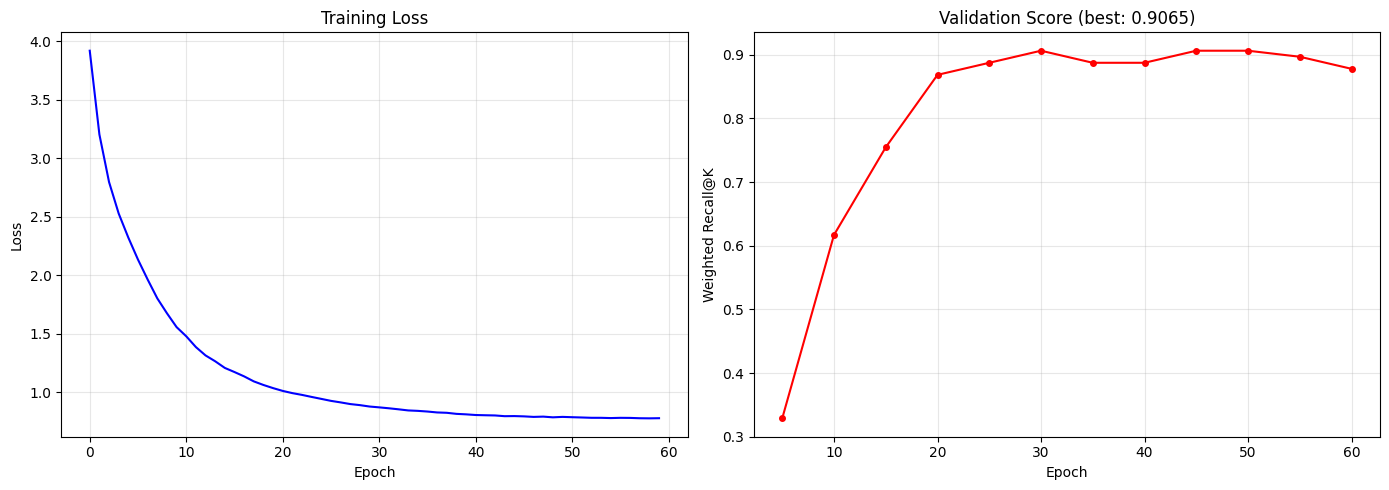

In [33]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['loss'], 'b-', linewidth=1.5)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training Loss')
ax1.grid(True, alpha=0.3)

val_epochs = [x[0] for x in history['val_score']]
val_scores = [x[1] for x in history['val_score']]
ax2.plot(val_epochs, val_scores, 'r-o', linewidth=1.5, markersize=4)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Weighted Recall@K')
ax2.set_title(f'Validation Score (best: {best_val_score:.4f})')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Generate Test Submission

In [34]:
# ======================== LOAD BEST EMA MODEL ========================
checkpoint = torch.load('best_model.pth', map_location=cfg.device, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Loaded best model from epoch {checkpoint['epoch']} — Val score: {checkpoint['val_score']:.4f}")

Loaded best model from epoch 30 — Val score: 0.9065


In [35]:
# ======================== GENERATE TEST SUBMISSION ========================

@torch.no_grad()
def generate_submission(model, test_dir, cfg, output_path='submission.csv', use_tta=True):
    """Generate final Kaggle submission CSV."""
    model.eval()
    results = []
    
    for batch_id in tqdm(range(1, 31), desc='Generating submission'):
        batch_dir = os.path.join(test_dir, str(batch_id))
        
        with open(os.path.join(batch_dir, 'text.txt')) as f:
            query = f.read().strip()
        
        motion_files = sorted(
            [f for f in os.listdir(batch_dir) if f.endswith('.npy')],
            key=lambda x: int(x.replace('motion_', '').replace('.npy', ''))
        )
        
        motions, motion_indices = [], []
        for mf in motion_files:
            motion = np.load(os.path.join(batch_dir, mf))
            idx = int(mf.replace('motion_', '').replace('.npy', ''))
            motions.append(torch.FloatTensor(motion))
            motion_indices.append(idx)
        
        max_len = max(m.shape[0] for m in motions)
        padded = torch.zeros(len(motions), max_len, cfg.motion_dim)
        masks = torch.zeros(len(motions), max_len, dtype=torch.bool)
        lengths = torch.zeros(len(motions), dtype=torch.long)
        for i, m in enumerate(motions):
            padded[i, :m.shape[0]] = m
            masks[i, :m.shape[0]] = True
            lengths[i] = m.shape[0]
        
        padded = padded.to(cfg.device)
        masks = masks.to(cfg.device)
        lengths = lengths.to(cfg.device)
        
        with torch.amp.autocast('cuda', enabled=cfg.use_amp):
            motion_emb = model.motion_encoder(padded, masks, lengths)
            
            if use_tta:
                padded_swap = torch.cat([padded[:, :, 192:], padded[:, :, :192]], dim=2)
                motion_emb_swap = model.motion_encoder(padded_swap, masks, lengths)
                motion_emb = F.normalize(motion_emb + motion_emb_swap, dim=-1)
            
            text_emb = model.text_encoder([query])
        
        sim = (motion_emb.float() @ text_emb.float().t()).squeeze(-1)
        ranked_indices = sim.argsort(descending=True).cpu().numpy()
        top10 = [motion_indices[i] for i in ranked_indices[:10]]
        
        results.append([batch_id] + top10)
    
    df = pd.DataFrame(
        results,
        columns=['query_id'] + [f'candidate_{i}' for i in range(1, 11)]
    )
    df.to_csv(output_path, index=False)
    print(f"\nSubmission saved to {output_path}")
    print(f"Shape: {df.shape}")
    print(df.head(10))
    return df


# Generate submission
submission_df = generate_submission(model, cfg.test_dir, cfg, use_tta=True)

Generating submission: 100%|██████████| 30/30 [00:09<00:00,  3.07it/s]


Submission saved to submission.csv
Shape: (30, 11)
   query_id  candidate_1  candidate_2  candidate_3  candidate_4  candidate_5  \
0         1           15           30            9           17           10   
1         2           24           11           31            3           10   
2         3           30           18            4           28            5   
3         4           31           20            7           27           24   
4         5            4           24            3           28           20   
5         6           30           19           12           18            6   
6         7           22           15           12            9           23   
7         8            6           19           15           20           22   
8         9           11           31           19           16           10   
9        10           31           19            4            1           11   

   candidate_6  candidate_7  candidate_8  candidate_9  candidate_10

In [36]:
# ======================== SANITY CHECKS ========================

# Verify no duplicate candidates per query
for _, row in submission_df.iterrows():
    candidates = row[[f'candidate_{i}' for i in range(1, 11)]].values
    assert len(candidates) == len(set(candidates)), f"Duplicate found in query {row['query_id']}!"

print("All checks passed! Submission is valid.")

All checks passed! Submission is valid.


In [37]:
import pandas as pd
import csv

def ultimate_rank_blend(file_86, file_83, output_file="submission_086_083_fusion.csv", weight_86=0.65, weight_83=0.35):
    print(f"⚗️ Lancement de la Fusion Ultime :")
    print(f"  - Modèle Champion (Poids {weight_86}) : {file_86}")
    print(f"  - Modèle Challenger (Poids {weight_83}) : {file_83}")
    
    # Lecture des fichiers
    df_86 = pd.read_csv(file_86)
    df_83 = pd.read_csv(file_83)
    
    # Vérification de sécurité
    assert len(df_86) == len(df_83), "Erreur : Les fichiers n'ont pas la même taille !"
    
    final_scores = {}
    
    # On itère sur les deux fichiers avec leurs poids respectifs
    models = [(df_86, weight_86), (df_83, weight_83)]
    
    for df, w in models:
        for i in range(len(df)):
            row = df.iloc[i]
            qid = row['query_id']
            
            if qid not in final_scores:
                final_scores[qid] = {}
            
            # Les 10 candidats
            candidates = row.values[1:] 
            
            # Vote de Borda (Le 1er gagne 10 pts, le 10ème 1 pt) * Le poids du modèle
            for rank, cid in enumerate(candidates):
                points = (10 - rank) * w
                if cid in final_scores[qid]:
                    final_scores[qid][cid] += points
                else:
                    final_scores[qid][cid] = points

    # Écriture de la nouvelle soumission
    submission_rows = []
    sorted_qids = sorted(final_scores.keys())
    
    for qid in sorted_qids:
        candidates_scores = final_scores[qid]
        # Tri des candidats par score final décroissant
        sorted_candidates = sorted(candidates_scores.items(), key=lambda x: x[1], reverse=True)
        
        # On extrait le Top 10
        top_10 = [c[0] for c in sorted_candidates[:10]]
        
        # Filet de sécurité (si < 10 candidats uniques, on complète avec le modèle fort)
        if len(top_10) < 10:
            for cid in df_86[df_86['query_id'] == qid].values[0][1:]:
                if cid not in top_10:
                    top_10.append(cid)
                if len(top_10) == 10:
                    break
                    
        submission_rows.append([qid] + top_10)

    # Sauvegarde au format Kaggle
    header = ['query_id'] + [f'candidate_{i}' for i in range(1, 11)]
    with open(output_file, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(header)
        writer.writerows(submission_rows)
        
    print(f"✅ Fichier d'ensemble généré avec succès : {output_file}")

# ==========================================
# EXÉCUTION
# ==========================================
# Remplace les noms par tes vrais fichiers CSV
fichier_champion = "/kaggle/input/datasets/missawb/submission_y/submission_finale_ultimate.csv" 
fichier_challenger = "/kaggle/working/submission.csv"

ultimate_rank_blend(
    file_86=fichier_champion, 
    file_83=fichier_challenger, 
    output_file="submission_finale_ultimate.csv",
    weight_86=0.60,
    weight_83=0.40
)

⚗️ Lancement de la Fusion Ultime :
  - Modèle Champion (Poids 0.6) : /kaggle/input/datasets/missawb/submission_y/submission_finale_ultimate.csv
  - Modèle Challenger (Poids 0.4) : /kaggle/working/submission.csv


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/missawb/submission_y/submission_finale_ultimate.csv'